# 04 · Product Application: Targeting Under Behavioral Change

**Role in the project:** this is the *downstream product application*. Notebooks 02–03 study how customer behavior changes,
whether that change can be represented as states, and whether state-aware models are more reliable; this notebook asks whether behavioral-change information helps a real decision —
**who should receive a marketing message** — using the randomized X5 experiment.

**Question:** Do temporal / change features ("adaptive") pick better customers to message than a conventional customer profile ("static"),
and does that hold across contact budgets and across levels of behavioral instability?

**Design:** historical purchases (pre-treatment) → randomized SMS (`treatment_flg`) → purchase afterwards (`target`).
Because treatment is randomized, the difference in purchase rates between treated and control customers *within any group selected
using pre-treatment features* is an unbiased estimate of the treatment effect in that group.

This is a cleaned version of `archive/03_product_targeting_draft.ipynb` (originally `02_modeling_draft.ipynb`). It keeps the final pipeline and the
locked test results and drops exploratory dead ends (the first adaptive model with leaky instability, and the unfinished PyTorch model).
The draft is kept unchanged as history.

## 1 · Setup, features, split

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import norm
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, log_loss

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

FIG_DIR = Path("../figures")
FIG_DIR.mkdir(exist_ok=True)

model_data = pd.read_parquet("../data/processed/model_data.parquet")
print(model_data.shape)

(200039, 46)


**Two customer representations.**

- **Static (8 features):** each behavior averaged over E1–E4, plus history depth. A conventional customer profile: uses all
  pre-treatment history but ignores *when* things happened.
- **Adaptive (41 features):** the 24 period-specific values, trends, recent deviations, behavioral instability, category drift
  (with missing-value indicators), and history depth. Same information, but keeps the temporal ordering and change signals.

Category drift is missing when a customer has no purchases in the relevant periods; it is filled with 0 **plus** a 0/1 indicator
so the model can tell "no drift" from "not measurable".

In [2]:
BEHAVIOR = ["transactions", "total_spend", "avg_basket_spend",
            "total_quantity", "avg_quantity", "avg_unique_products"]
PERIODS = ["E1", "E2", "E3", "E4"]

for f in BEHAVIOR:
    model_data[f"{f}_static_mean"] = model_data[[f"{f}_{p}" for p in PERIODS]].mean(axis=1)

static_features = [f"{f}_static_mean" for f in BEHAVIOR] + ["historical_category_lines", "history_periods_active"]

drift_features = ["category_drift_E1_E3", "category_drift_E3_E4", "category_drift_history_E4"]
for f in drift_features:
    model_data[f"{f}_missing"] = model_data[f].isna().astype(int)
    model_data[f] = model_data[f].fillna(0)

# Adaptive feature order matches the draft exactly (tree models can depend on column order for tie-breaking)
adaptive_features = [f"{f}_{p}" for f in BEHAVIOR for p in PERIODS]
adaptive_features += [f"{f}_trend" for f in ["transactions", "total_spend", "avg_basket_spend", "total_quantity"]]
adaptive_features += [f"{f}_recent_deviation" for f in ["transactions", "total_spend", "avg_basket_spend", "total_quantity"]]
adaptive_features += drift_features + ["historical_category_lines", "history_periods_active"]
adaptive_features += [f"{f}_missing" for f in drift_features]
adaptive_features += ["behavioral_instability_clean"]   # computed after the split (train statistics only)

print("Static:", len(static_features), "| Adaptive:", len(adaptive_features))

Static: 8 | Adaptive: 41


In [3]:
# 60 / 20 / 20 split, stratified on treatment x outcome (identical to notebooks 02–03)
model_data["stratify_group"] = model_data["treatment_flg"].astype(str) + "_" + model_data["target"].astype(str)

train_data, temp_data = train_test_split(model_data, test_size=0.40, random_state=42,
                                         stratify=model_data["stratify_group"])
val_data, test_data = train_test_split(temp_data, test_size=0.50, random_state=42,
                                       stratify=temp_data["stratify_group"])
print("Train:", train_data.shape, "| Val:", val_data.shape, "| Test:", test_data.shape)

Train: (120023, 56) | Val: (40008, 56) | Test: (40008, 56)


**Behavioral instability (leakage-free).** Each customer's four recent deviations (E4 minus E1–E3 average) are standardized using
**training-set** mean and standard deviation, and instability = mean absolute z-score. (An earlier version standardized with the whole
dataset, which leaks a little information from validation/test into the features; that version is not used here.)

In [4]:
deviation_features = ["transactions_recent_deviation", "total_spend_recent_deviation",
                      "avg_basket_spend_recent_deviation", "total_quantity_recent_deviation"]

train_dev_stats = {f: (train_data[f].mean(), train_data[f].std()) for f in deviation_features}

def add_clean_instability(df):
    df = df.copy()
    z = pd.DataFrame({f: (df[f] - mu) / sd for f, (mu, sd) in train_dev_stats.items()})
    df["behavioral_instability_clean"] = z.abs().mean(axis=1)
    return df

train_data, val_data, test_data = (add_clean_instability(d) for d in (train_data, val_data, test_data))

# Instability quartile thresholds from TRAIN only, applied to every split
q25, q50, q75 = train_data["behavioral_instability_clean"].quantile([0.25, 0.50, 0.75])
GROUP_ORDER = ["Q1 Stable", "Q2", "Q3", "Q4 High Change"]

def instability_group(x):
    return np.select([x <= q25, x <= q50, x <= q75], GROUP_ORDER[:3], default=GROUP_ORDER[3])

for d in (train_data, val_data, test_data):
    d["instability_group"] = instability_group(d["behavioral_instability_clean"])

print("Train thresholds:", round(q25, 3), round(q50, 3), round(q75, 3))

Train thresholds: 0.286 0.473 0.77


## 2 · The experiment itself

Before any modeling: what does messaging *everyone* do? Difference in purchase rates, treated minus control, with a normal-approximation
95% confidence interval. This is the "random targeting" benchmark every model must beat.

In [5]:
def ate_with_ci(df):
    t = df.loc[df["treatment_flg"] == 1, "target"]
    c = df.loc[df["treatment_flg"] == 0, "target"]
    ate = t.mean() - c.mean()
    se = np.sqrt(t.mean() * (1 - t.mean()) / len(t) + c.mean() * (1 - c.mean()) / len(c))
    z = ate / se
    return {"control_rate": c.mean(), "treated_rate": t.mean(), "ate": ate,
            "ci_low": ate - 1.96 * se, "ci_high": ate + 1.96 * se,
            "p_value": 2 * (1 - norm.cdf(abs(z))), "relative_lift": ate / c.mean()}

pd.DataFrame({"all": ate_with_ci(model_data), "train": ate_with_ci(train_data),
              "val": ate_with_ci(val_data), "test": ate_with_ci(test_data)}).T.round(4)

,control_rate,treated_rate,ate,ci_low,ci_high,p_value,relative_lift
all,0.6033,0.6365,0.0332,0.0290,0.0375,0.0,0.0551
train,0.6033,0.6365,0.0332,0.0277,0.0387,0.0,0.0551
val,0.6033,0.6365,0.0332,0.0237,0.0427,0.0,0.0551
test,0.6033,0.6365,0.0332,0.0237,0.0427,0.0,0.0551


Messaging raises purchase probability by about **3.3 percentage points** (≈ +5.5% relative), so random messaging yields
≈ **332 incremental purchases per 10,000 messages**. The split preserves this exactly in every subset.

## 3 · Evaluation tools

- **Policy value at a budget:** rank customers by a model score, message the top *b*% (10–50%), and measure the treated-minus-control
  purchase rate *inside that selected group*. Reported as incremental purchases per 10,000 messages. Randomization makes this valid.
- **Qini-style excess area:** a single summary of the whole ranking. Cumulative incremental purchases as more customers are targeted,
  integrated over 0–100% targeted, minus the area for random targeting. Higher = better overall ranking.
- **Bootstrap:** resample customers with replacement to see how much a difference between two models could move by chance.

In [6]:
def selected_effect(df, scores, budget):
    cutoff = np.quantile(scores, 1 - budget)
    sel = df[scores >= cutoff]
    ate = (sel.loc[sel["treatment_flg"] == 1, "target"].mean()
           - sel.loc[sel["treatment_flg"] == 0, "target"].mean())
    return len(sel), ate

def policy_table(df, scores, budgets=(0.10, 0.20, 0.30, 0.40, 0.50)):
    rows = []
    for b in budgets:
        n, ate = selected_effect(df, np.asarray(scores), b)
        rows.append({"budget": b, "n_targeted": n, "ate": ate, "incremental_per_10k": ate * 10_000})
    return pd.DataFrame(rows)

def compare_policies(df, scores_a, scores_b, name_a="static", name_b="adaptive"):
    a = policy_table(df, scores_a).set_index("budget")["incremental_per_10k"].rename(f"{name_a}_per_10k")
    b = policy_table(df, scores_b).set_index("budget")["incremental_per_10k"].rename(f"{name_b}_per_10k")
    out = pd.concat([a, b], axis=1)
    out[f"{name_b}_minus_{name_a}"] = out.iloc[:, 1] - out.iloc[:, 0]
    return out

def cumulative_gain_curve(df, scores, n_points=100):
    ev = df[["treatment_flg", "target"]].copy()
    ev["score"] = np.asarray(scores)
    ev = ev.sort_values("score", ascending=False).reset_index(drop=True)
    rows = [{"fraction_targeted": 0.0, "cumulative_gain": 0.0}]
    for frac in np.linspace(0.01, 1.0, n_points):
        n = max(1, int(len(ev) * frac))
        sel = ev.iloc[:n]
        ate = (sel.loc[sel["treatment_flg"] == 1, "target"].mean()
               - sel.loc[sel["treatment_flg"] == 0, "target"].mean())
        rows.append({"fraction_targeted": frac, "cumulative_gain": ate * n})
    return pd.DataFrame(rows)

def qini_excess(df, scores):
    curve = cumulative_gain_curve(df, scores)
    auuc = np.trapezoid(curve["cumulative_gain"], curve["fraction_targeted"])
    overall_ate = ate_with_ci(df)["ate"]
    random_auuc = overall_ate * len(df) / 2
    return auuc - random_auuc, curve

def bootstrap_difference(df, col_a, col_b, budget=0.20, n_boot=2000, random_state=42):
    """Bootstrap the difference (b minus a) in selected-group treatment effect."""
    rng = np.random.default_rng(random_state)
    diffs = []
    for _ in range(n_boot):
        boot = df.iloc[rng.integers(0, len(df), len(df))]
        _, ate_a = selected_effect(boot, boot[col_a].to_numpy(), budget)
        _, ate_b = selected_effect(boot, boot[col_b].to_numpy(), budget)
        diffs.append(ate_b - ate_a)
    diffs = np.array(diffs)
    return {"difference_per_10k": diffs.mean() * 1e4,
            "ci_lower_per_10k": np.percentile(diffs, 2.5) * 1e4,
            "ci_upper_per_10k": np.percentile(diffs, 97.5) * 1e4,
            "prob_b_better": (diffs > 0).mean()}

## 4 · Baseline: predicting *who buys* is not the same as *who is persuaded*

A logistic regression on the static profile predicts purchase. We then message the 20% most likely to buy.

In [7]:
response_model = Pipeline([("scaler", StandardScaler()),
                           ("model", LogisticRegression(max_iter=1000, random_state=42))])
response_model.fit(train_data[static_features], train_data["target"])
val_response = response_model.predict_proba(val_data[static_features])[:, 1]

print("Validation ROC-AUC:", round(roc_auc_score(val_data["target"], val_response), 4))
print("Validation log loss:", round(log_loss(val_data["target"], val_response), 4))
n, ate = selected_effect(val_data, val_response, 0.20)
print(f"Top 20% by purchase probability: {ate * 1e4:.0f} incremental purchases / 10K (random ≈ 332)")

Validation ROC-AUC: 0.7588
Validation log loss: 0.5664
Top 20% by purchase probability: 111 incremental purchases / 10K (random ≈ 332)


The model predicts purchasing well (AUC ≈ 0.76) yet its top 20% gain **less** from a message than a random 20%: these customers mostly
buy anyway. **Prediction accuracy ≠ decision quality.** This motivates modeling the *effect* of the message instead.

## 5 · Uplift models: static vs adaptive (validation)

**S-learner:** one gradient-boosting classifier predicts purchase from features **plus** `treatment_flg`. For each customer we predict twice —
once pretending they were messaged, once pretending they were not — and the difference is the estimated uplift. Customers are ranked by uplift.

Same model settings for both representations, so the only difference is the features. Validation is used for comparison; test is
touched once, in §7.

In [8]:
HGB_PARAMS = dict(learning_rate=0.05, max_iter=200, max_leaf_nodes=15,
                  min_samples_leaf=50, l2_regularization=1.0, random_state=42)

def fit_s_learner(train_df, features):
    model = HistGradientBoostingClassifier(**HGB_PARAMS)
    model.fit(train_df[features + ["treatment_flg"]], train_df["target"])
    return model

def s_learner_uplift(model, df, features):
    X = df[features + ["treatment_flg"]].copy()
    X["treatment_flg"] = 1
    p1 = model.predict_proba(X)[:, 1]
    X["treatment_flg"] = 0
    p0 = model.predict_proba(X)[:, 1]
    return p1 - p0

static_s = fit_s_learner(train_data, static_features)
adaptive_s = fit_s_learner(train_data, adaptive_features)

val_static_uplift = s_learner_uplift(static_s, val_data, static_features)
val_adaptive_uplift = s_learner_uplift(adaptive_s, val_data, adaptive_features)

compare_policies(val_data, val_static_uplift, val_adaptive_uplift).round(1)

,static_per_10k,adaptive_per_10k,adaptive_minus_static
budget,,,
0.1,742.1,717.2,-24.9
0.2,543.2,519.6,-23.6
0.3,438.7,502.2,63.4
0.4,443.4,546.4,103.0
0.5,443.4,473.3,29.9


In [9]:
val_static_qini, val_static_curve = qini_excess(val_data, val_static_uplift)
val_adaptive_qini, val_adaptive_curve = qini_excess(val_data, val_adaptive_uplift)
print(f"Validation Qini excess area — static: {val_static_qini:.2f} | adaptive: {val_adaptive_qini:.2f}")

Validation Qini excess area — static: 149.22 | adaptive: 197.60


**Validation reading.** Both uplift models beat random targeting (332/10K) and the response model at every budget.
In this run static is slightly ahead at 10–20% and adaptive ahead at 30–50%, with the larger Qini area. On validation alone, adaptive looks like the
better *overall* ranker. (§6b checks how much of this is luck.)

### Robustness check: T-learner (validation only)

A T-learner fits **two** models — one on treated customers, one on control — and takes the difference of their predictions.
It is a check that conclusions do not depend on the S-learner structure. It is not carried to the test set.

In [10]:
def fit_t_learner(train_df, features):
    treated = train_df[train_df["treatment_flg"] == 1]
    control = train_df[train_df["treatment_flg"] == 0]
    m1 = HistGradientBoostingClassifier(**HGB_PARAMS).fit(treated[features], treated["target"])
    m0 = HistGradientBoostingClassifier(**HGB_PARAMS).fit(control[features], control["target"])
    return m1, m0

def t_learner_uplift(models, df, features):
    m1, m0 = models
    return m1.predict_proba(df[features])[:, 1] - m0.predict_proba(df[features])[:, 1]

val_static_t = t_learner_uplift(fit_t_learner(train_data, static_features), val_data, static_features)
val_adaptive_t = t_learner_uplift(fit_t_learner(train_data, adaptive_features), val_data, adaptive_features)

compare_policies(val_data, val_static_t, val_adaptive_t).round(1)

,static_per_10k,adaptive_per_10k,adaptive_minus_static
budget,,,
0.1,452.7,602.6,149.9
0.2,406.4,484.8,78.4
0.3,388.8,499.3,110.5
0.4,433.8,483.6,49.8
0.5,370.3,447.7,77.4


The T-learner gives the same broad picture — adaptive is competitive or better at most budgets, with no consistent large advantage —
so the S-learner is kept as the main model (it is simpler and uses all data in one model).

## 6 · Final test evaluation (run once — results locked)

Models trained on train only, settings fixed before looking at test. This is **one run** (seed 42); §6b shows how much it varies.

In [11]:
test_static_uplift = s_learner_uplift(static_s, test_data, static_features)
test_adaptive_uplift = s_learner_uplift(adaptive_s, test_data, adaptive_features)

test_policy = compare_policies(test_data, test_static_uplift, test_adaptive_uplift)
test_policy["relative_improvement_%"] = 100 * test_policy["adaptive_minus_static"] / test_policy["static_per_10k"]
test_policy.round(1)

,static_per_10k,adaptive_per_10k,adaptive_minus_static,relative_improvement_%
budget,,,,
0.1,550.5,683.4,132.9,24.1
0.2,524.2,589.0,64.9,12.4
0.3,430.8,477.8,47.0,10.9
0.4,403.6,485.4,81.9,20.3
0.5,409.1,478.8,69.7,17.0


In [12]:
test_static_qini, test_static_curve = qini_excess(test_data, test_static_uplift)
test_adaptive_qini, test_adaptive_curve = qini_excess(test_data, test_adaptive_uplift)
print(f"Test Qini excess area — static: {test_static_qini:.2f} | adaptive: {test_adaptive_qini:.2f}")
print(f"Adaptive vs static: {100 * (test_adaptive_qini / test_static_qini - 1):+.1f}%")

Test Qini excess area — static: 110.63 | adaptive: 131.48
Adaptive vs static: +18.8%


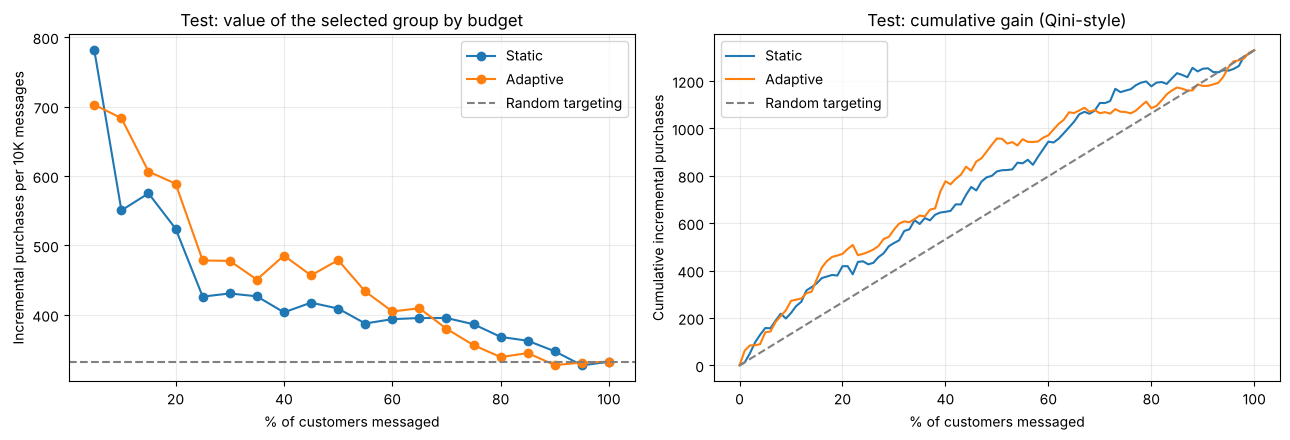

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

curve_pts = np.arange(0.05, 1.0001, 0.05)
for name, scores in [("Static", test_static_uplift), ("Adaptive", test_adaptive_uplift)]:
    vals = [selected_effect(test_data, scores, b)[1] * 1e4 for b in curve_pts]
    axes[0].plot(curve_pts * 100, vals, marker="o", label=name)
axes[0].axhline(ate_with_ci(test_data)["ate"] * 1e4, ls="--", color="grey", label="Random targeting")
axes[0].set(xlabel="% of customers messaged", ylabel="Incremental purchases per 10K messages",
            title="Test: value of the selected group by budget")
axes[0].legend(); axes[0].grid(alpha=0.25)

for name, curve in [("Static", test_static_curve), ("Adaptive", test_adaptive_curve)]:
    axes[1].plot(curve["fraction_targeted"] * 100, curve["cumulative_gain"], label=name)
axes[1].plot([0, 100], [0, ate_with_ci(test_data)["ate"] * len(test_data)], ls="--", color="grey", label="Random targeting")
axes[1].set(xlabel="% of customers messaged", ylabel="Cumulative incremental purchases",
            title="Test: cumulative gain (Qini-style)")
axes[1].legend(); axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.savefig(FIG_DIR / "04_test_targeting.png", dpi=130)
plt.show()

### Does the adaptive advantage depend on how much a customer's behavior changed?

Within each behavioral-instability quartile (thresholds from train), compare static vs adaptive at a 20% budget, with a bootstrap
confidence interval for the difference.

In [14]:
test_eval = test_data[["treatment_flg", "target", "instability_group"]].copy()
test_eval["static_uplift"] = test_static_uplift
test_eval["adaptive_uplift"] = test_adaptive_uplift

rows = []
for g in GROUP_ORDER:
    gdf = test_eval[test_eval["instability_group"] == g]
    _, s_ate = selected_effect(gdf, gdf["static_uplift"].to_numpy(), 0.20)
    _, a_ate = selected_effect(gdf, gdf["adaptive_uplift"].to_numpy(), 0.20)
    boot = bootstrap_difference(gdf, "static_uplift", "adaptive_uplift", budget=0.20, n_boot=2000)
    rows.append({"instability_group": g, "n_customers": len(gdf),
                 "static_per_10k": s_ate * 1e4, "adaptive_per_10k": a_ate * 1e4,
                 "adaptive_minus_static": (a_ate - s_ate) * 1e4,
                 "boot_ci_lower": boot["ci_lower_per_10k"], "boot_ci_upper": boot["ci_upper_per_10k"],
                 "prob_adaptive_better": boot["prob_b_better"]})
test_subgroups = pd.DataFrame(rows)
test_subgroups.round(2)

,instability_group,n_customers,static_per_10k,adaptive_per_10k,adaptive_minus_static,boot_ci_lower,boot_ci_upper,prob_adaptive_better
0,Q1 Stable,9997,645.62,669.73,24.10,-321.03,417.43,0.58
1,Q2,10124,523.80,785.80,261.99,-120.76,687.37,0.91
2,Q3,9830,325.53,340.87,15.34,-453.98,415.40,0.48
3,Q4 High Change,10057,450.96,235.76,-215.20,-686.83,262.82,0.18


## 6b · How stable are these results? (seed sensitivity)

`HistGradientBoostingClassifier` sets aside a random 10% of the training data to decide when to stop adding trees
(early stopping). Its `random_state` controls *which* 10%. Nothing else changes: same data, same features, same split, same settings.

If a conclusion flips when only this seed changes, it is not a reliable conclusion. We refit both S-learners with seeds 0–9 and record
validation and test results for each. (This re-uses the test set, but no choice is made from it: we are measuring variability, not tuning.)

In [15]:
def run_seed(seed):
    params = {**HGB_PARAMS, "random_state": seed}
    out = {"seed": seed}
    uplifts = {}
    for name, feats in [("static", static_features), ("adaptive", adaptive_features)]:
        m = HistGradientBoostingClassifier(**params).fit(train_data[feats + ["treatment_flg"]], train_data["target"])
        for split, df in [("val", val_data), ("test", test_data)]:
            u = s_learner_uplift(m, df, feats)
            uplifts[(split, name)] = u
            out[f"{split}_{name}_qini"] = qini_excess(df, u)[0]
            for b in (0.10, 0.20, 0.30, 0.40, 0.50):
                out[f"{split}_{name}_{int(b * 100)}"] = selected_effect(df, u, b)[1] * 1e4
    # instability subgroups on test at 20%
    for g in GROUP_ORDER:
        mask = (test_data["instability_group"] == g).to_numpy()
        gdf = test_data[mask]
        s = selected_effect(gdf, uplifts[("test", "static")][mask], 0.20)[1]
        a = selected_effect(gdf, uplifts[("test", "adaptive")][mask], 0.20)[1]
        out[f"test_{g}_diff"] = (a - s) * 1e4
    return out

seed_results = pd.DataFrame([run_seed(s) for s in range(10)])

def summarize(split, metrics):
    rows = []
    for k in metrics:
        st, ad = seed_results[f"{split}_static_{k}"], seed_results[f"{split}_adaptive_{k}"]
        diff = ad - st
        rows.append({"metric": k if k == "qini" else f"top {k}%", "static_mean": st.mean(), "adaptive_mean": ad.mean(),
                     "diff_mean": diff.mean(), "diff_min": diff.min(), "diff_max": diff.max(),
                     "adaptive_wins_of_10": int((diff > 0).sum())})
    return pd.DataFrame(rows)

METRICS = ["10", "20", "30", "40", "50", "qini"]
print("VALIDATION")
display(summarize("val", METRICS).round(1))
print("TEST")
display(summarize("test", METRICS).round(1))

VALIDATION


,metric,static_mean,adaptive_mean,diff_mean,diff_min,diff_max,adaptive_wins_of_10
0,top 10%,621.2,679.9,58.8,-95.1,301.0,7
1,top 20%,517.4,577.2,59.8,-56.3,195.5,8
2,top 30%,441.0,531.1,90.2,-31.7,199.0,9
3,top 40%,397.8,478.9,81.1,6.5,126.1,10
4,top 50%,416.3,451.7,35.4,3.9,75.8,10
5,qini,129.3,179.3,50.0,7.3,85.3,10


TEST


,metric,static_mean,adaptive_mean,diff_mean,diff_min,diff_max,adaptive_wins_of_10
0,top 10%,635.4,667.5,32.2,-125.3,235.9,6
1,top 20%,480.4,551.6,71.2,-10.0,211.2,9
2,top 30%,416.1,500.7,84.6,-2.4,146.7,9
3,top 40%,426.3,457.6,31.3,-20.7,100.3,8
4,top 50%,413.6,407.8,-5.9,-38.3,84.1,2
5,qini,116.1,120.2,4.1,-45.7,73.0,3


In [16]:
sub = pd.DataFrame({g: seed_results[f"test_{g}_diff"] for g in GROUP_ORDER})
pd.DataFrame({"mean_adaptive_minus_static": sub.mean(), "min": sub.min(), "max": sub.max(),
              "adaptive_wins_of_10": (sub > 0).sum()}).round(1)

,mean_adaptive_minus_static,min,max,adaptive_wins_of_10
Q1 Stable,-2.6,-240.0,180.0,5
Q2,119.9,-230.8,350.8,9
Q3,-16.1,-222.4,302.5,4
Q4 High Change,-31.5,-190.8,93.4,4


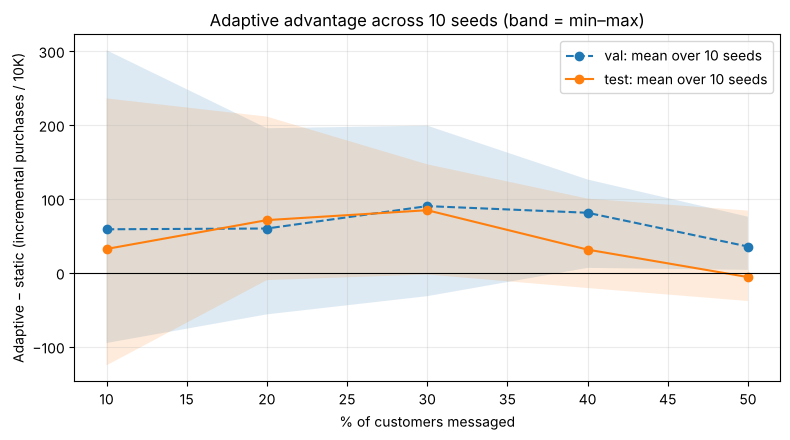

In [17]:
fig, ax = plt.subplots(figsize=(8, 4.5))
budgets = ["10", "20", "30", "40", "50"]
for split, style in [("val", "--"), ("test", "-")]:
    d = np.array([seed_results[f"{split}_adaptive_{b}"] - seed_results[f"{split}_static_{b}"] for b in budgets])
    x = [int(b) for b in budgets]
    ax.plot(x, d.mean(axis=1), style, marker="o", label=f"{split}: mean over 10 seeds")
    ax.fill_between(x, d.min(axis=1), d.max(axis=1), alpha=0.15)
ax.axhline(0, color="black", lw=0.8)
ax.set(xlabel="% of customers messaged", ylabel="Adaptive − static (incremental purchases / 10K)",
       title="Adaptive advantage across 10 seeds (band = min–max)")
ax.legend(); ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(FIG_DIR / "04_seed_sensitivity.png", dpi=130)
plt.show()

### 6b · Reading the seed results

- **Single runs are not reliable here.** With identical data and settings, the adaptive-minus-static gap at a 10% budget ranges from
  about −125 to +236 purchases per 10K on test depending only on the early-stopping seed. Top-10% groups contain only ~4,000 customers
  (≈2,000 control), so their measured effect is noisy, and small changes in the model reorder who lands in them.
- **What is stable:** on test, adaptive beats static at **20% and 30% budgets in 9 of 10 seeds** (mean ≈ +71 and +85 per 10K, roughly +15–20%).
- **What is not stable:** the 10% budget (adaptive wins 6/10), 50% (2/10), and the overall Qini area (3/10, mean difference ≈ +4 — a tie).
- **Validation vs test disagreement is stable:** adaptive has the larger Qini area on validation in **10/10** seeds but only **3/10** on test.
  The advantage seen on validation for the overall ranking does not carry over to new customers.
- **The instability-subgroup pattern is not stable:** the Q4 (highest-change) reversal reported in the draft appears in some seeds but not others
  (adaptive wins 4/10, mean ≈ −32 per 10K); only Q2 shows a consistent adaptive advantage (9/10).

**Relation to the draft's numbers.** The draft reported, from one run, ≈ +26% at 10%, Qini −9.7%, and Q4 −348 per 10K. The 10% and Qini values lie
inside the seed spread above; the Q4 value is more extreme than any of the 10 re-runs (range ≈ −191 to +93). None could be reproduced
exactly here (different scikit-learn version → different early-stopping holdout).
The conclusions below replace the single-run headlines.

## 6c · Does message response differ by behavioral state?

Notebooks 02–03 define four behavioral states and the E3 → E4 transition for each customer (enrolled cohort). Here we ask:
**does the message's effect differ by the customer's current state, or by whether their state just changed?**

**Method.** Within each group, treated − control purchase rate (the treatment effect, in percentage points) with a 95% confidence interval.
Because treatment is randomized, each group's estimate is unbiased. No model is fitted, so all uplift customers in the cohort are used.
Differences between two groups are tested with a z-test on the difference of their effects.

**Interpretation rule.** States are *observed*, not assigned. A larger effect for Light customers means *Light customers respond more*, not
that *being Light causes* stronger response — those customers differ in many ways. With 9 state × group cells, a few p < 0.05 differences are
expected by chance; only large, consistent patterns are interpreted.

In [18]:
state_table = pd.read_parquet("../data/processed/customer_states.parquet")
cohort = model_data.merge(state_table[["client_id", "state_E3", "state_E4"]], on="client_id")
cohort["transition_group"] = np.select(
    [cohort["state_E3"] == "Inactive", cohort["state_E3"] != cohort["state_E4"]], ["reactivated", "changed"], default="stable")
print("Cohort customers with states:", len(cohort))

def effect(d):
    t = d.loc[d["treatment_flg"] == 1, "target"]
    c = d.loc[d["treatment_flg"] == 0, "target"]
    ate = t.mean() - c.mean()
    se = np.sqrt(t.var() / len(t) + c.var() / len(c))
    return pd.Series({"customers": len(d), "control_rate": c.mean(), "effect_pp": 100 * ate,
                      "ci_low": 100 * (ate - 1.96 * se), "ci_high": 100 * (ate + 1.96 * se), "se_pp": 100 * se})

def diff_test(a, b):
    d = a["effect_pp"] - b["effect_pp"]
    se = np.sqrt(a["se_pp"] ** 2 + b["se_pp"] ** 2)
    return {"difference_pp": d, "ci_low": d - 1.96 * se, "ci_high": d + 1.96 * se, "p_value": 2 * (1 - norm.cdf(abs(d / se)))}

E4_ORDER = ["Light", "Stock-up", "Frequent"]
GROUP_ORDER_T = ["stable", "changed", "reactivated"]
by_state = cohort.groupby("state_E4").apply(effect, include_groups=False).reindex(E4_ORDER)
by_group = cohort.groupby("transition_group").apply(effect, include_groups=False).reindex(GROUP_ORDER_T)
print("By current (E4) state")
display(by_state.round(2))
print("By E3 → E4 transition")
by_group.round(2)

Cohort customers with states: 177600
By current (E4) state


,customers,control_rate,effect_pp,ci_low,ci_high,se_pp
state_E4,,,,,,
Light,48195.0,0.44,5.02,4.13,5.91,0.45
Stock-up,65319.0,0.52,2.40,1.64,3.17,0.39
Frequent,64086.0,0.81,1.87,1.28,2.46,0.30


By E3 → E4 transition


,customers,control_rate,effect_pp,ci_low,ci_high,se_pp
transition_group,,,,,,
stable,100427.0,0.67,2.70,2.12,3.27,0.29
changed,54966.0,0.60,3.41,2.60,4.23,0.41
reactivated,22207.0,0.31,4.14,2.91,5.38,0.63


In [19]:
pd.DataFrame({
    "Light − Frequent": diff_test(by_state.loc["Light"], by_state.loc["Frequent"]),
    "Light − Stock-up": diff_test(by_state.loc["Light"], by_state.loc["Stock-up"]),
    "Stock-up − Frequent": diff_test(by_state.loc["Stock-up"], by_state.loc["Frequent"]),
    "changed − stable": diff_test(by_group.loc["changed"], by_group.loc["stable"]),
    "reactivated − stable": diff_test(by_group.loc["reactivated"], by_group.loc["stable"]),
}).T.round(3)

,difference_pp,ci_low,ci_high,p_value
Light − Frequent,3.157,2.089,4.225,0.000
Light − Stock-up,2.618,1.445,3.792,0.000
Stock-up − Frequent,0.539,-0.427,1.504,0.275
changed − stable,0.719,-0.274,1.711,0.156
reactivated − stable,1.448,0.085,2.810,0.037


In [20]:
by_cell = cohort.groupby(["state_E4", "transition_group"]).apply(effect, include_groups=False)
display(by_cell.reindex(pd.MultiIndex.from_product([E4_ORDER, GROUP_ORDER_T])).round(2))

within = pd.DataFrame({f"{s}: changed − stable": diff_test(by_cell.loc[(s, "changed")], by_cell.loc[(s, "stable")])
                       for s in E4_ORDER}).T
within.round(3)

customers  control_rate  effect_pp  ci_low  ci_high  se_pp
Light    stable         21478.0          0.47       6.38    5.05     7.72   0.68
         changed        17436.0          0.52       3.74    2.26     5.22   0.75
         reactivated     9281.0          0.26       4.70    2.88     6.53   0.93
Stock-up stable         37676.0          0.58       1.46    0.46     2.45   0.51
         changed        16687.0          0.56       3.00    1.49     4.50   0.77
         reactivated    10956.0          0.29       4.80    3.06     6.53   0.88
Frequent stable         41273.0          0.87       1.36    0.72     2.00   0.32
         changed        20843.0          0.72       3.11    1.91     4.31   0.61
         reactivated     1970.0          0.66      -1.43   -5.63     2.76   2.14

,difference_pp,ci_low,ci_high,p_value
Light: changed − stable,-2.640,-4.633,-0.647,0.009
Stock-up: changed − stable,1.538,-0.263,3.339,0.094
Frequent: changed − stable,1.750,0.395,3.105,0.011


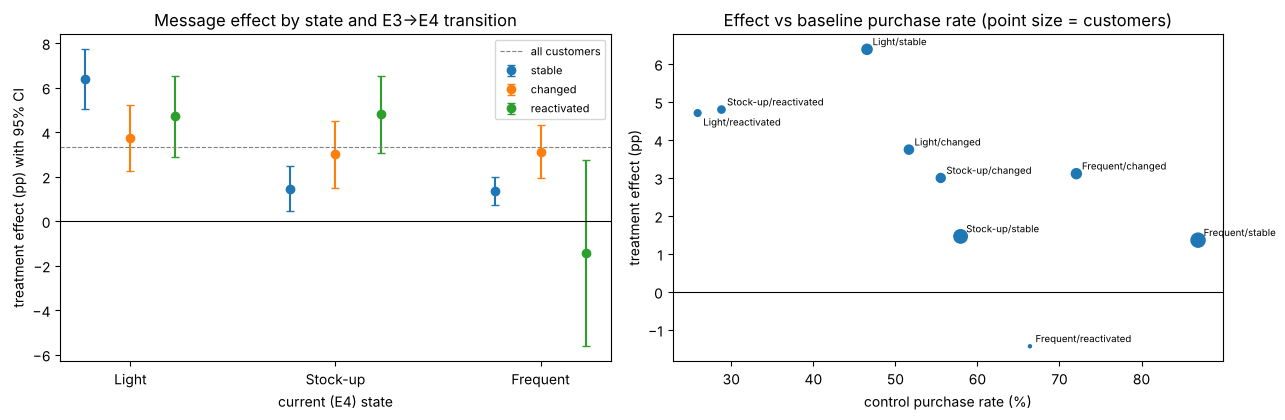

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))

cells = by_cell.reindex(pd.MultiIndex.from_product([E4_ORDER, GROUP_ORDER_T]))
x = np.arange(len(E4_ORDER))
for i, g in enumerate(GROUP_ORDER_T):
    vals = cells.xs(g, level=1)
    axes[0].errorbar(x + (i - 1) * 0.22, vals["effect_pp"],
                     yerr=[vals["effect_pp"] - vals["ci_low"], vals["ci_high"] - vals["effect_pp"]],
                     fmt="o", capsize=3, label=g)
axes[0].axhline(0, color="black", lw=0.8)
axes[0].axhline(100 * ate_with_ci(model_data)["ate"], color="grey", ls="--", lw=0.8, label="all customers")
axes[0].set_xticks(x, E4_ORDER)
axes[0].set(ylabel="treatment effect (pp) with 95% CI", xlabel="current (E4) state",
            title="Message effect by state and E3→E4 transition")
axes[0].legend(fontsize=8)

pts = cells.dropna()
axes[1].scatter(100 * pts["control_rate"], pts["effect_pp"], s=pts["customers"] / 400)
for k, ((s, g), r) in enumerate(pts.iterrows()):
    axes[1].annotate(f"{s}/{g}", (100 * r["control_rate"], r["effect_pp"]), fontsize=7,
                     xytext=(4, -9 if g == "reactivated" and s == "Light" else 3), textcoords="offset points")
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set(xlabel="control purchase rate (%)", ylabel="treatment effect (pp)",
            title="Effect vs baseline purchase rate (point size = customers)")
plt.tight_layout()
plt.savefig(FIG_DIR / "04_effect_by_state.png", dpi=130)
plt.show()

### 6c · Reading the results

1. **Current state matters a lot.** Light customers respond to the message with ≈ +5.0 pp, Stock-up ≈ +2.4 pp, Frequent ≈ +1.9 pp.
   Light − Frequent ≈ +3.2 pp is far outside chance. Messaging effort is worth more on customers who currently shop little.
2. **"Changed vs stable" overall is not clearly different** (≈ 3.4 vs 2.7 pp; CI includes 0). Reactivated customers respond ≈ 4.1 pp.
3. **Within states the direction flips.** Customers who just *became* Frequent or Stock-up respond more than those who were already there
   (≈ +1.7 and +1.5 pp more), while those who just became Light respond *less* than long-term Light customers (≈ −2.6 pp).
   These cell-level differences are individually borderline and should be read as a pattern, not as separate findings.
4. **"Headroom" explains part of this, not all of it.** The group that buys almost surely anyway (always-Frequent: 87% buy without a message)
   gains the least, which fits a ceiling effect. But the largest effect is in always-Light customers at a middle baseline (≈ 47%), and the
   lowest-baseline groups (reactivated, ≈ 26–29%) are not the highest. Baseline purchase rate is one factor among others; this is a description,
   not a causal mechanism. The reactivated − stable difference (p ≈ 0.04) is borderline given the number of comparisons.

**For the targeting decision.** Behavioral state is a cheap, readable segmentation that already separates high- and low-response customers by a
factor of ≈ 2.5. Together with notebook 03 (stale profiles mis-predict customers who changed), it suggests targeting should rely on *current* behavior,
and that the state label is a useful way to explain *who* is being selected.

## 7 · Conclusions

1. **Predicting purchase ≠ choosing whom to message.** The response model (AUC ≈ 0.76) selects customers who gain *less* than average
   from a message (≈ 111 vs 332 incremental purchases per 10K).
2. **Adaptive (temporal/change) features give a modest, fairly consistent gain for mid-sized budgets:** ≈ +70–90 incremental purchases
   per 10K messages at 20–30% budgets on test, in 9 of 10 seeds.
3. **They do not improve the overall ranking on new data:** the Qini-style area is essentially tied on test, even though validation favored
   adaptive in every seed. More temporal information did not make the model more robust overall.
4. **Very selective targeting (10%) is too noisy to call** at this sample size; a single run can show either model winning by 20%+.
5. **No reliable evidence that the adaptive advantage depends on behavioral instability.** The earlier "fails under extreme change"
   pattern does not survive re-running with different seeds.

6. **Response differs strongly by behavioral state** (§6c): Light customers gain ≈ +5 pp from a message vs ≈ +2 pp for Frequent ones,
   partly consistent with differences in headroom. Whether a customer *just changed* state matters less clearly and in different directions by state.

**Methodological lesson (worth keeping in the write-up).** A result that depended on one random seed looked like a clear finding
(+26% at 10%; adaptive fails for high-change customers). Repeating the fit with different seeds showed which parts were real.
This is the same theme as notebook 02 (§D): an apparent signal can come from the measurement process rather than the customers.

**Connection to notebooks 02–03.** Notebook 03 asks the cleaner version of the question this notebook could not settle: does explicitly
representing behavioral states and transitions explain where a model stays reliable?

**Limitations.**
- One train/val/test split; seed variation captures model randomness, not sampling variation of customers (the bootstrap covers part of that).
- Behavioral change measures are observational; only the message is randomized. We cannot say changing behavior *causes* a different response.
- Neither model was tuned; the shared settings are reasonable defaults.
- Exact SMS timing is not documented in the source data; only the ordering "history → message → outcome" is relied on.